In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL

load_dotenv(".env", override=True)

url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM patients", engine)
print(df.shape)

(297, 14)


In [3]:
query = """
SELECT
    CASE WHEN sex = 1 THEN 'Male' ELSE 'Female' END AS sex_label,
    COUNT(*) AS patients,
    ROUND(AVG(target) * 100, 1) AS disease_rate_pct
FROM patients
GROUP BY sex
"""
print(pd.read_sql(query, engine))

  sex_label  patients  disease_rate_pct
0    Female        96              26.0
1      Male       201              55.7


In [4]:
query = """
SELECT
    cp,
    COUNT(*) AS patients,
    ROUND(AVG(target) * 100, 1) AS disease_rate_pct
FROM patients
GROUP BY cp
ORDER BY cp
"""
print(pd.read_sql(query, engine))

   cp  patients  disease_rate_pct
0   1        23              30.4
1   2        49              18.4
2   3        83              21.7
3   4       142              72.5


### Finding: Chest pain type
Asymptomatic patients had the highest disease rate (72.5%), more than double any other group.
This likely reflects selection bias: every patient was referred for cardiac testing, so those
without chest pain were referred for other warning signs.

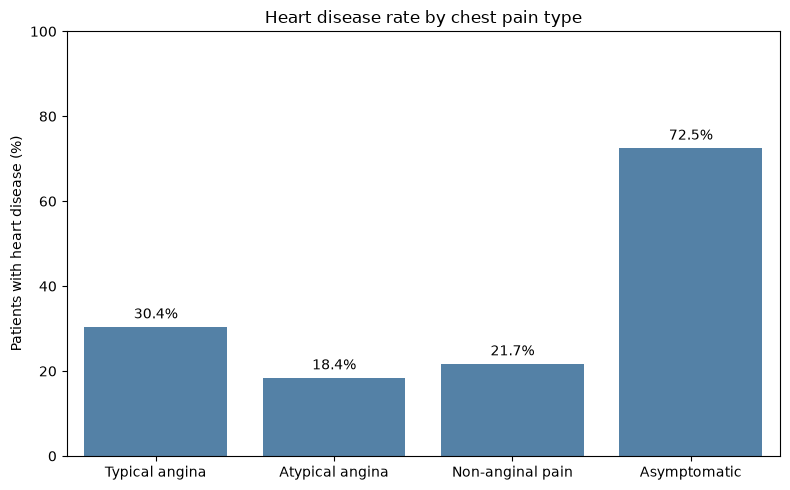

In [5]:
cp_rates = pd.read_sql(query, engine)
cp_rates["cp_label"] = cp_rates["cp"].map({
    1: "Typical angina",
    2: "Atypical angina",
    3: "Non-anginal pain",
    4: "Asymptomatic",
})

plt.figure(figsize=(8, 5))
sns.barplot(data=cp_rates, x="cp_label", y="disease_rate_pct", color="steelblue")
plt.title("Heart disease rate by chest pain type")
plt.xlabel("")
plt.ylabel("Patients with heart disease (%)")
plt.ylim(0, 100)

for i, value in enumerate(cp_rates["disease_rate_pct"]):
    plt.text(i, value + 2, f"{value}%", ha="center")

plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/disease_rate_by_chest_pain.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
query = """
SELECT
    CASE
        WHEN age < 45 THEN '1. Under 45'
        WHEN age < 55 THEN '2. 45-54'
        WHEN age < 65 THEN '3. 55-64'
        ELSE '4. 65+'
    END AS age_group,
    COUNT(*) AS patients,
    ROUND(AVG(target) * 100, 1) AS disease_rate_pct
FROM patients
GROUP BY age_group
ORDER BY age_group
"""
print(pd.read_sql(query, engine))

     age_group  patients  disease_rate_pct
0  1. Under 45        53              24.5
1     2. 45-54        85              34.1
2     3. 55-64       118              63.6
3       4. 65+        41              48.8


In [8]:
query = """
SELECT
    target,
    ROUND(AVG(age), 1) AS avg_age,
    ROUND(AVG(trestbps), 1) AS avg_resting_bp,
    ROUND(AVG(chol), 1) AS avg_cholesterol,
    ROUND(AVG(thalach), 1) AS avg_max_heart_rate
FROM patients
GROUP BY target
"""
print(pd.read_sql(query, engine))

   target  avg_age  avg_resting_bp  avg_cholesterol  avg_max_heart_rate
0       0     52.6           129.2            243.5               158.6
1       1     56.8           134.6            251.9               139.1


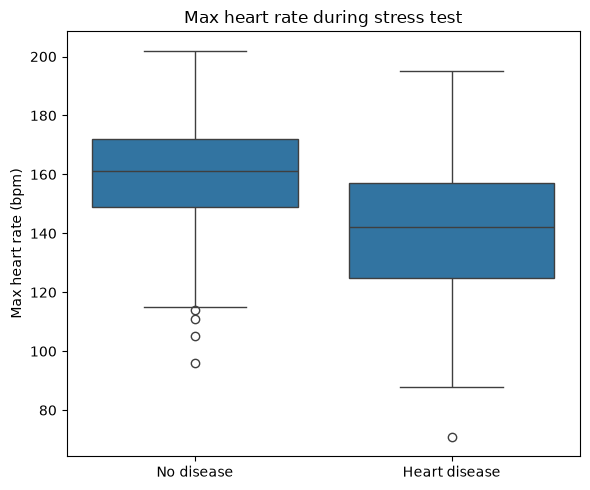

In [9]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="target", y="thalach")
plt.xticks([0, 1], ["No disease", "Heart disease"])
plt.title("Max heart rate during stress test")
plt.xlabel("")
plt.ylabel("Max heart rate (bpm)")
plt.tight_layout()
plt.savefig("images/max_heart_rate_by_target.png", dpi=150, bbox_inches="tight")
plt.show()

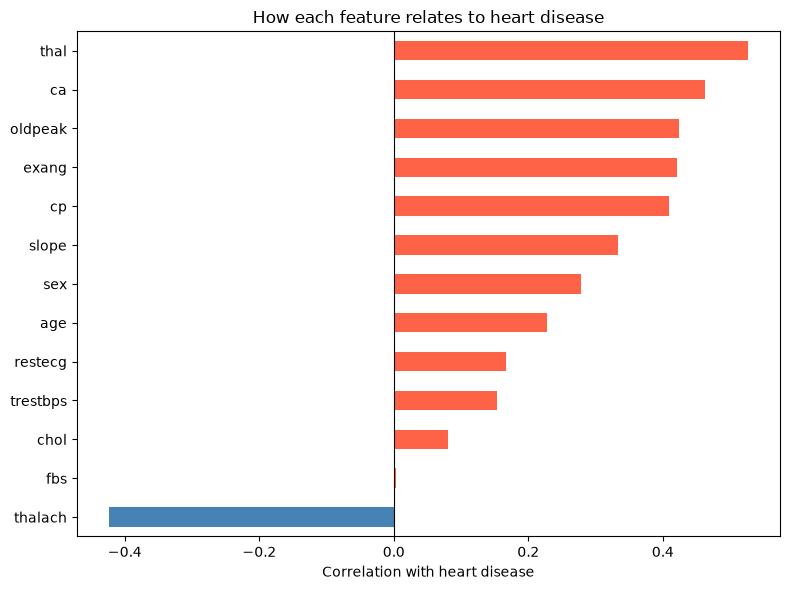

In [10]:
target_corr = df.corr()["target"].drop("target").sort_values()

colors = ["tomato" if value > 0 else "steelblue" for value in target_corr]

plt.figure(figsize=(8, 6))
target_corr.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("How each feature relates to heart disease")
plt.xlabel("Correlation with heart disease")
plt.tight_layout()
plt.savefig("images/correlation_with_target.png", dpi=150, bbox_inches="tight")
plt.show()

# Exploratory Data Analysis: UCI Heart Disease (Cleveland)

**Data:** 297 patients referred for cardiac testing, 13 clinical features, 46% with heart disease.

**Key findings**
- Asymptomatic patients had the highest disease rate (72.5%), likely due to referral bias.
- Disease rate rises with age through 64 (63.6%); the 65+ group is small (41 patients).
- Max heart rate during stress testing is ~12% lower in patients with disease.
- Cholesterol barely separates the groups in this referred population.
- The strongest signals come from stress test and imaging results, so the model is
  suited to clinicians with test results, not public self-screening.